# Smart Room: Logistic Regression vs XGBoost
Compare the two existing experiments on identical observations and four sensor inputs. Each model is fitted only on training data; its setting is selected by validation occupied-class F1. The test set is used to report the final comparison, not to choose new settings.

Train: February 2-11, 2015 (11,360 rows). Validation: February 12-15 (5,760 rows). Test: February 16-18 (3,440 rows).

Keep this notebook and the three CSVs together. Install missing dependencies with `%pip install pandas numpy scikit-learn xgboost matplotlib`, then restart the kernel. No automatic installation runs. Executing this notebook creates a `comparison_outputs` folder containing tables and PNG charts.

The individual LR and XGBoost notebooks remain separate. No Macro F1 or always-unoccupied baseline is included. This is a descriptive comparison on a test set whose results have already been inspected, not a fresh blind benchmark.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, balanced_accuracy_score,
                             confusion_matrix, roc_auc_score)

DATA_DIR = Path('.')
OUTPUT_DIR = Path('comparison_outputs')
OUTPUT_DIR.mkdir(exist_ok=True)
FEATURES = ['Temperature', 'Humidity', 'Light', 'CO2']
TARGET = 'Occupancy'
SEED = 42

## 1. Load and validate the same three splits
These checks reproduce the split checks in the individual notebooks. Date is not a predictor.

In [2]:
specs = {
    'Train': ('Occupancy_Train.csv', '2015-02-02', '2015-02-11', 11360),
    'Validation': ('Occupancy_Validation.csv', '2015-02-12', '2015-02-15', 5760),
    'Test': ('Occupancy_Test.csv', '2015-02-16', '2015-02-18', 3440),
}
expected_columns = ['date', 'Temperature', 'Humidity', 'Light',
                    'CO2', 'HumidityRatio', 'Occupancy']
datasets = {}
split_rows = []
for name, (filename, start, end, expected_rows) in specs.items():
    df = pd.read_csv(DATA_DIR / filename, parse_dates=['date'])
    assert list(df.columns) == expected_columns, f'{name}: unexpected columns'
    assert len(df) == expected_rows, f'{name}: unexpected row count'
    assert not df.isna().any().any(), f'{name}: missing cells'
    assert df['date'].is_monotonic_increasing, f'{name}: timestamps not sorted'
    assert not df['date'].duplicated().any(), f'{name}: repeated timestamps'
    assert df['date'].between(pd.Timestamp(start), pd.Timestamp(end) + pd.Timedelta(days=1), inclusive='left').all()
    assert df[TARGET].isin([0, 1]).all(), f'{name}: invalid target'
    assert set(df[TARGET].unique()) == {0, 1}, f'{name}: only one class'
    assert np.isfinite(df[FEATURES].to_numpy(dtype=float)).all()
    datasets[name] = df
    split_rows.append({'Split': name, 'Rows': len(df),
                       'First timestamp': str(df['date'].min()),
                       'Last timestamp': str(df['date'].max()),
                       'Unoccupied': int(df[TARGET].eq(0).sum()),
                       'Occupied': int(df[TARGET].eq(1).sum()),
                       'Occupied %': round(df[TARGET].mean() * 100, 2)})

assert datasets['Train']['date'].max() < datasets['Validation']['date'].min()
assert datasets['Validation']['date'].max() < datasets['Test']['date'].min()
assert pd.concat(datasets.values())['date'].nunique() == 20560
print(pd.DataFrame(split_rows).to_string(index=False))
print('Verified: chronological splits, no shared timestamps, all 20,560 rows accounted for.')

     Split  Rows     First timestamp      Last timestamp  Unoccupied  Occupied  Occupied %
     Train 11360 2015-02-02 14:19:00 2015-02-11 23:58:59        8445      2915       25.66
Validation  5760 2015-02-12 00:00:00 2015-02-15 23:58:59        5022       738       12.81
      Test  3440 2015-02-16 00:00:00 2015-02-18 09:19:00        2343      1097       31.89
Verified: chronological splits, no shared timestamps, all 20,560 rows accounted for.


In [3]:
X_train, y_train = datasets['Train'][FEATURES], datasets['Train'][TARGET]
X_val, y_val = datasets['Validation'][FEATURES], datasets['Validation'][TARGET]
X_test, y_test = datasets['Test'][FEATURES], datasets['Test'][TARGET]

def evaluate(y_true, predictions, probabilities=None):
    result = {
        'Accuracy': accuracy_score(y_true, predictions),
        'Precision': precision_score(y_true, predictions, zero_division=0),
        'Recall': recall_score(y_true, predictions, zero_division=0),
        'F1': f1_score(y_true, predictions, zero_division=0),
        'Balanced accuracy': balanced_accuracy_score(y_true, predictions),
    }
    if probabilities is not None:
        result['ROC AUC'] = roc_auc_score(y_true, probabilities)
    return result

## 2. Select logistic regression using validation only
Compare C = 0.01, 0.1, 1, 10. Fit StandardScaler and LR only on training data. Select highest occupied-class validation F1; ties favor smaller C. Keep the selected training-fitted pipeline.

In [4]:
candidate_models = {}
validation_rows = []
for C in [0.01, 0.1, 1.0, 10.0]:
    model = Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', LogisticRegression(C=C, max_iter=1000, random_state=SEED)),
    ])
    model.fit(X_train, y_train)
    assert model.named_steps['classifier'].n_iter_.max() < 1000, 'Check convergence'
    val_prob = model.predict_proba(X_val)[:, 1]
    val_pred = model.predict(X_val)
    validation_rows.append({'C': C, **evaluate(y_val, val_pred, val_prob)})
    candidate_models[C] = model

validation_results = pd.DataFrame(validation_rows).sort_values(
    ['F1', 'C'], ascending=[False, True]).reset_index(drop=True)
best_C = float(validation_results.loc[0, 'C'])
best_model = candidate_models[best_C]
print(validation_results.round(4).to_string(index=False))
print(f'Selected C = {best_C:g} using validation F1 only.')

lr_model = best_model
lr_C = best_C
lr_validation_results = validation_results.copy()
lr_validation_results.to_csv(OUTPUT_DIR / 'lr_validation.csv', index=False)

    C  Accuracy  Precision  Recall     F1  Balanced accuracy  ROC AUC
 0.10    0.9915     0.9492  0.9864 0.9674             0.9893   0.9946
10.00    0.9913     0.9503  0.9837 0.9667             0.9881   0.9944
 1.00    0.9911     0.9490  0.9837 0.9661             0.9880   0.9944
 0.01    0.9887     0.9265  0.9905 0.9574             0.9895   0.9960
Selected C = 0.1 using validation F1 only.


## 3. Select XGBoost using validation only
Compare depths 1, 2, 3, 4 with 100 boosting rounds and learning rate 0.1. Other settings match the XGBoost notebook. Ties favor shallower depth. Trees do not need LR's StandardScaler. This is a model-appropriate preprocessing difference, not a change of input features.

In [5]:
candidate_models = {}
validation_rows = []
for depth in [1, 2, 3, 4]:
    model = XGBClassifier(
        objective='binary:logistic',
        n_estimators=100,
        max_depth=depth,
        learning_rate=0.1,
        reg_lambda=1.0,
        min_child_weight=1,
        subsample=1.0,
        colsample_bytree=1.0,
        scale_pos_weight=1.0,
        tree_method='hist',
        device='cpu',
        n_jobs=2,
        eval_metric='logloss',
        random_state=SEED,
    )
    model.fit(X_train, y_train)
    val_prob = model.predict_proba(X_val)[:, 1]
    val_pred = (val_prob >= 0.5).astype(int)
    validation_rows.append({'Max depth': depth, **evaluate(y_val, val_pred, val_prob)})
    candidate_models[depth] = model

validation_results = pd.DataFrame(validation_rows).sort_values(
    ['F1', 'Max depth'], ascending=[False, True]).reset_index(drop=True)
best_depth = int(validation_results.loc[0, 'Max depth'])
best_model = candidate_models[best_depth]
print(validation_results.round(4).to_string(index=False))
print(f'Selected max_depth = {best_depth} using validation occupied-class F1.')

xgb_model = best_model
xgb_depth = best_depth
xgb_validation_results = validation_results.copy()
xgb_validation_results.to_csv(OUTPUT_DIR / 'xgb_validation.csv', index=False)

 Max depth  Accuracy  Precision  Recall     F1  Balanced accuracy  ROC AUC
         1    0.9918     0.9481  0.9905 0.9689             0.9913   0.9951
         2    0.9918     0.9481  0.9905 0.9689             0.9913   0.9947
         4    0.9319     0.6547  0.9919 0.7888             0.9575   0.9913
         3    0.9309     0.6529  0.9837 0.7849             0.9534   0.9811
Selected max_depth = 1 using validation occupied-class F1.


## 4. Compare on the identical test rows
LR uses its default predict rule; XGBoost uses probability >= 0.5, as in its individual notebook. Precision, recall and F1 are for occupied class 1. Count-based error measures accompany percentages. No new tuning uses test outcomes.

In [6]:
models = {'Logistic regression': lr_model, 'XGBoost': xgb_model}
predictions = {}
matrices = {}
rows = []
for name, model in models.items():
    probability = model.predict_proba(X_test)[:, 1]
    predicted = model.predict(X_test) if name == 'Logistic regression' else (probability >= 0.5).astype(int)
    predictions[name] = predicted
    cm = confusion_matrix(y_test, predicted, labels=[0, 1])
    matrices[name] = cm
    tn, fp, fn, tp = cm.ravel()
    rows.append({'Model': name, **evaluate(y_test, predicted, probability),
                 'False alarms': int(fp), 'Missed occupied': int(fn),
                 'Total errors': int(fp + fn)})

comparison = pd.DataFrame(rows).set_index('Model')
comparison.to_csv(OUTPUT_DIR / 'test_comparison.csv')
presentation_table = comparison.copy()
score_columns = ['Accuracy', 'Precision', 'Recall', 'F1', 'Balanced accuracy']
presentation_table[score_columns] = presentation_table[score_columns] * 100
presentation_table = presentation_table.rename(columns={c: c + ' (%)' for c in score_columns})
print(presentation_table.round(2).to_string())
print(f'Selected settings: LR C={lr_C:g}; XGBoost max_depth={xgb_depth}.')

                     Accuracy (%)  Precision (%)  Recall (%)  F1 (%)  Balanced accuracy (%)  ROC AUC  False alarms  Missed occupied  Total errors
Model                                                                                                                                            
Logistic regression         99.36          98.12       99.91   99.01                  99.51      1.0            21                1            22
XGBoost                     99.48          98.65       99.73   99.18                  99.54      1.0            15                3            18
Selected settings: LR C=0.1; XGBoost max_depth=1.


## 5. Confusion matrices side by side
Rows are actual labels; columns are predicted labels. Both plots use the same color scale and record counts. Focus on false occupancy alarms (top right) and missed occupied readings (bottom left).

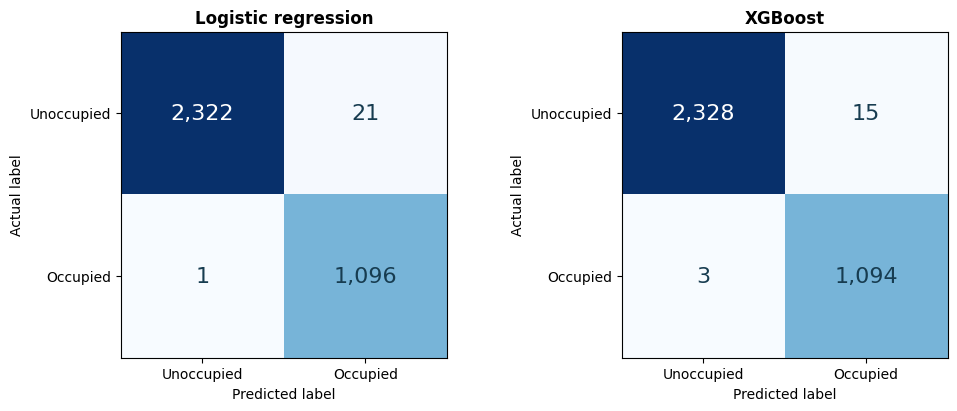

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
vmax = max(cm.max() for cm in matrices.values())
for ax, (name, cm) in zip(axes, matrices.items()):
    ax.imshow(cm, cmap='Blues', vmin=0, vmax=vmax)
    for (i, j), value in np.ndenumerate(cm):
        ax.text(j, i, f'{value:,}', ha='center', va='center', fontsize=16,
                color='white' if value > vmax * 0.5 else '#173C50')
    ax.set_xticks([0, 1], ['Unoccupied', 'Occupied'])
    ax.set_yticks([0, 1], ['Unoccupied', 'Occupied'])
    ax.set_xlabel('Predicted label')
    ax.set_ylabel('Actual label')
    ax.set_title(name, fontweight='bold')
fig.savefig(OUTPUT_DIR / 'confusion_matrices.png', dpi=180, bbox_inches='tight')
plt.show()

## 6. Precision, recall and F1
Bars use a full 0-100% scale to avoid exaggerating the small differences. Exact labels and the table make differences visible. All three metrics refer to occupied readings.

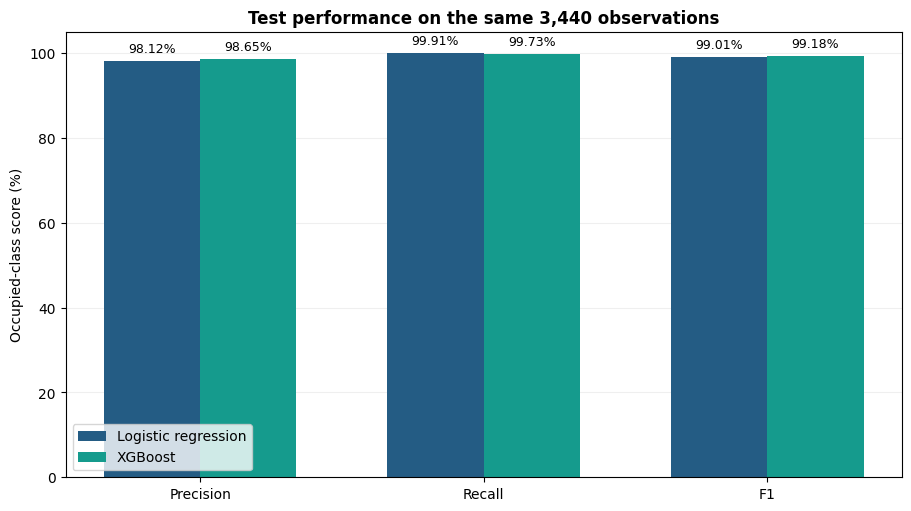

In [8]:
metrics = ['Precision', 'Recall', 'F1']
x = np.arange(len(metrics))
fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
width = 0.34
for offset, (name, color) in zip([-width / 2, width / 2],
                               [('Logistic regression', '#245C84'), ('XGBoost', '#159B8D')]):
    values = comparison.loc[name, metrics].to_numpy(dtype=float) * 100
    bars = ax.bar(x + offset, values, width=width, label=name, color=color)
    ax.bar_label(bars, labels=[f'{v:.2f}%' for v in values], padding=4, fontsize=9)
ax.set_xticks(x, metrics)
ax.set_ylim(0, 105)
ax.set_yticks(np.arange(0, 101, 20))
ax.set_ylabel('Occupied-class score (%)')
ax.set_title('Test performance on the same 3,440 observations', fontweight='bold')
ax.legend(loc='lower left')
ax.grid(axis='y', alpha=0.2)
ax.set_axisbelow(True)
fig.savefig(OUTPUT_DIR / 'metric_comparison.png', dpi=180, bbox_inches='tight')
plt.show()

## 7. Training and validation diagnostic
Compare selected models on training and validation, without retuning. A gap can reflect overfitting and/or changes between periods. It is not a formal guarantee about generalization.

In [9]:
diagnostic_rows = []
for name, model in models.items():
    for split_name, X, y in [('Training', X_train, y_train), ('Validation', X_val, y_val)]:
        probability = model.predict_proba(X)[:, 1]
        predicted = model.predict(X) if name == 'Logistic regression' else (probability >= 0.5).astype(int)
        diagnostic_rows.append({'Model': name, 'Split': split_name, **evaluate(y, predicted, probability)})
fit_diagnostics = pd.DataFrame(diagnostic_rows)
fit_diagnostics.to_csv(OUTPUT_DIR / 'training_validation.csv', index=False)
print(fit_diagnostics.round(4).to_string(index=False))

              Model      Split  Accuracy  Precision  Recall     F1  Balanced accuracy  ROC AUC
Logistic regression   Training    0.9861     0.9512  0.9969 0.9735             0.9896   0.9934
Logistic regression Validation    0.9915     0.9492  0.9864 0.9674             0.9893   0.9946
            XGBoost   Training    0.9859     0.9518  0.9955 0.9732             0.9891   0.9978
            XGBoost Validation    0.9918     0.9481  0.9905 0.9689             0.9913   0.9951


## 8. Interpret the comparison
Report small differences and the tradeoff between false alarms and missed occupancy. Fewer errors overall does not establish that a model is best for every application. This comparison has no significance test; neighboring minute readings are correlated, and only a short recording is covered.

In [10]:
lr_result = comparison.loc['Logistic regression']
xgb_result = comparison.loc['XGBoost']
f1_difference = (xgb_result['F1'] - lr_result['F1']) * 100
print(f"LR: {int(lr_result['False alarms'])} false alarms, {int(lr_result['Missed occupied'])} missed occupied, {int(lr_result['Total errors'])} errors.")
print(f"XGBoost: {int(xgb_result['False alarms'])} false alarms, {int(xgb_result['Missed occupied'])} missed occupied, {int(xgb_result['Total errors'])} errors.")
print(f'XGBoost minus LR occupied F1: {f1_difference:+.2f} percentage points.')
print('Read the table to assess the accuracy/precision/F1 versus recall tradeoff.')
print('This is an observed result for this test period, not proof of universal superiority.')

LR: 21 false alarms, 1 missed occupied, 22 errors.
XGBoost: 15 false alarms, 3 missed occupied, 18 errors.
XGBoost minus LR occupied F1: +0.18 percentage points.
Read the table to assess the accuracy/precision/F1 versus recall tradeoff.
This is an observed result for this test period, not proof of universal superiority.
